<a href="https://colab.research.google.com/github/Parvez152977/SMS_Spam_Detection-Naive_Bayes_-_Logistic_Regression-/blob/main/SMS_spam_detection_V_2_(Parvez_Alam).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project: SMS Spam Detection
### Team Member :
                  1. Parvez Alam (111223046)
                  2. Siyma Akter (111223071)
### Dataset     : [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)
### Algorithm   : Multinomial Naive Bayes, Logistic Regression
### Environment : Google Colab(Python 3.13)

## Project Workflow

| Step | Description |
|------|-------------|
| 1 | Problem Definition |
| 2 | Data Collection |
| 3 | Data Cleaning & Preprocessing |
| 4 | Exploratory Data Analysis |
| 5 | Feature Engineering (CountVectorizer / TF-IDF) |
| 6 | Model Training (Naive Bayes, Logistic Regression) |
| 7 | Model Evaluation |
| 8 | Prediction on Custom Messages |
| 9 | Training vs Testing Analysis + Feature Importance |

# Machine learning Life cycle - 1: Problem Definition - SMS Spam Detection

### Environment Info (for reproducibility)

In [371]:
import sys
import platform


### Required libraries

In [372]:
import pandas as pd
import numpy as np
import sklearn
import nltk
import matplotlib
import seaborn


In [373]:
print("ENVIRONMENT INFORMATION")
print("=" * 55)
print(f"Platform       : {platform.system()} {platform.release()}")
print(f"Python version : {sys.version.split()[0]}")
print(f"Python binary  : {sys.executable}")
print("=" * 55)
print("LIBRARY VERSIONS")
print("=" * 55)
print(f"pandas         : {pd.__version__}")
print(f"numpy          : {np.__version__}")
print(f"scikit-learn   : {sklearn.__version__}")
print(f"nltk           : {nltk.__version__}")
print(f"matplotlib     : {matplotlib.__version__}")
print(f"seaborn        : {seaborn.__version__}")
print("=" * 55)

ENVIRONMENT INFORMATION
Platform       : Linux 6.6.159+
Python version : 3.13.18
Python binary  : /usr/bin/python3
LIBRARY VERSIONS
pandas         : 2.2.3
numpy          : 2.4.6
scikit-learn   : 1.6.1
nltk           : 3.9.1
matplotlib     : 3.10.0
seaborn        : 0.13.2


##### Report random state used for reproducibility

In [374]:
print("\nREPRODUCIBILITY SETTINGS")
print("=" * 55)
print("Random state   : 42  (used in train_test_split)")
print("Train-test     : 80:20")
print("Max features   : 2500 (CountVectorizer & TfidfVectorizer)")


REPRODUCIBILITY SETTINGS
Random state   : 42  (used in train_test_split)
Train-test     : 80:20
Max features   : 2500 (CountVectorizer & TfidfVectorizer)


# Initial Setup

In [375]:
import pandas as pd

## Machine Learning Life cycle - Step 2-> Data collection

In [376]:
file_path = '/content/drive/MyDrive/Machine_learning_dataset/SMSSpamCollection'

#### Operation in following command:
1. Load the dataset
2. sep='\t' means Tab-Separated
3. header=None means the file has no column names in the first row
4. names=['label', 'message'] gives our columns names manually

In [377]:
df = pd.read_csv(file_path, sep='\t', header=None, names=['label', 'message'])
print("Dataset loaded successfully!")

Dataset loaded successfully!


Now check the dataframe df

In [378]:
df

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


#### Following commands display the first 5 rows to verify it worked

In [379]:
print("Shape of data:", df.shape)

Shape of data: (5572, 2)


In [380]:
print("First 5 rows:")
print(df.head())

First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


Check the balance of the classes (How many spam vs ham?)

In [381]:
print("Class Distribution:")
print(df['label'].value_counts())

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


# Step 3 - Data Cleaning & Preprocessing

In [382]:
import nltk
import re
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

#### Following command download stopwords (only needs to be done once)

In [383]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

#### Following command initialize the stemmer

In [384]:
ps = PorterStemmer()

#### Create a list to hold our cleaned messages and loop through every message in the dataset

 #### Remove all characters except a-z and A-Z (keep only letters)
 #### re.sub replaces anything that is NOT a letter with a space

In [385]:
corpus = []
for i in range(0, len(df)):
      review = re.sub('[^a-zA-Z]', ' ', df['message'][i])

      review = review.lower()

      review = review.split()

      review = [ps.stem(word) for word in review if not word in stopwords.words('english')]
      # We only keep words that are NOT in the stopwords list

      review = ' '.join(review)

      corpus.append(review)

In [386]:
print(corpus[:50])

['go jurong point crazi avail bugi n great world la e buffet cine got amor wat', 'ok lar joke wif u oni', 'free entri wkli comp win fa cup final tkt st may text fa receiv entri question std txt rate c appli', 'u dun say earli hor u c alreadi say', 'nah think goe usf live around though', 'freemsg hey darl week word back like fun still tb ok xxx std chg send rcv', 'even brother like speak treat like aid patent', 'per request mell mell oru minnaminungint nurungu vettam set callertun caller press copi friend callertun', 'winner valu network custom select receivea prize reward claim call claim code kl valid hour', 'mobil month u r entitl updat latest colour mobil camera free call mobil updat co free', 'gonna home soon want talk stuff anymor tonight k cri enough today', 'six chanc win cash pound txt csh send cost p day day tsandc appli repli hl info', 'urgent week free membership prize jackpot txt word claim c www dbuk net lccltd pobox ldnw rw', 'search right word thank breather promis wont 

#### Now we convert the labels: ham = 0, spam = 1
#### We use map() to replace the text labels with numbers

In [387]:
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

In [388]:
df

,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,1
5568,ham,Will ü b going to esplanade fr home?,0
5569,ham,"Pity, * was in mood for that. So...any other s...",0
5570,ham,The guy did some bitching but I acted like i'd...,0


#### Let's see the difference between the original and cleaned message

In [389]:
print("Original Message (Row 2):")
print(df['message'][2])

Original Message (Row 2):
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


In [390]:
print("\nCleaned Message (Row 2):")
print(corpus[2])


Cleaned Message (Row 2):
free entri wkli comp win fa cup final tkt st may text fa receiv entri question std txt rate c appli


In [391]:
print("\n" + "="*50)
print("Original Message (Row 10 - likely spam):")
print(df['message'][10])
print("\nCleaned Message (Row 10):")
print(corpus[10])


Original Message (Row 10 - likely spam):
I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today.

Cleaned Message (Row 10):
gonna home soon want talk stuff anymor tonight k cri enough today


# Step 4: Exploratory Data Analysis (EDA)

In [392]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

## 1. Visualize Class Balance

/tmp/ipykernel_2568/2356780416.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


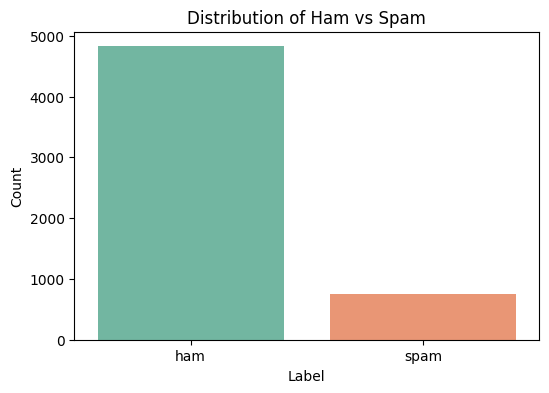

In [393]:
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Distribution of Ham vs Spam')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

## 2. Message Length Analysis

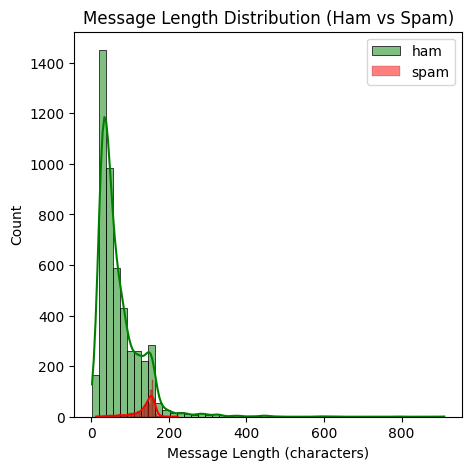

In [394]:
df['length'] = df['message'].apply(len)

plt.figure(figsize=(5,5))
sns.histplot(df[df['label']=='ham']['length'], bins=50, color='green', label='ham', kde=True)
sns.histplot(df[df['label']=='spam']['length'], bins=50, color='red', label='spam', kde=True)
plt.title('Message Length Distribution (Ham vs Spam)')
plt.xlabel('Message Length (characters)')
plt.legend()
plt.show()


In [395]:
print("Average length of HAM messages:", df[df['label']=='ham']['length'].mean())
print("Average length of SPAM messages:", df[df['label']=='spam']['length'].mean())


Average length of HAM messages: 71.48248704663213
Average length of SPAM messages: 138.6706827309237


### 3. Most Common Words in SPAM

In [396]:
# Separate the cleaned corpus into spam and ham

spam_words = ' '.join([corpus[i] for i in range(len(df)) if df['label_num'][i] == 1]).split()
ham_words  = ' '.join([corpus[i] for i in range(len(df)) if df['label_num'][i] == 0]).split()

In [397]:
print("\nTop 15 words in SPAM:")
print(Counter(spam_words).most_common(15))

print("\nTop 15 words in HAM:")
print(Counter(ham_words).most_common(15))


Top 15 words in SPAM:
[('call', 395), ('free', 228), ('u', 186), ('txt', 183), ('p', 180), ('text', 146), ('ur', 144), ('mobil', 142), ('stop', 128), ('claim', 115), ('repli', 113), ('www', 98), ('prize', 97), ('get', 90), ('min', 90)]

Top 15 words in HAM:
[('u', 1042), ('go', 425), ('get', 368), ('gt', 318), ('lt', 316), ('call', 300), ('come', 300), ('ok', 288), ('love', 256), ('day', 251), ('know', 249), ('like', 248), ('ur', 247), ('good', 236), ('time', 235)]


### 4. Word Clouds

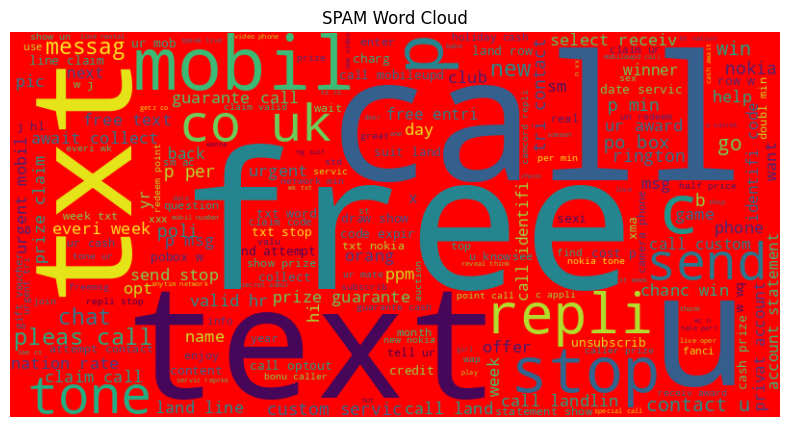

In [398]:
# Spam word cloud

spam_wc = WordCloud(width=800, height=400, background_color='red').generate(' '.join(spam_words))
plt.figure(figsize=(10,5))
plt.imshow(spam_wc, interpolation='bilinear')
plt.axis('off')
plt.title('SPAM Word Cloud')
plt.show()

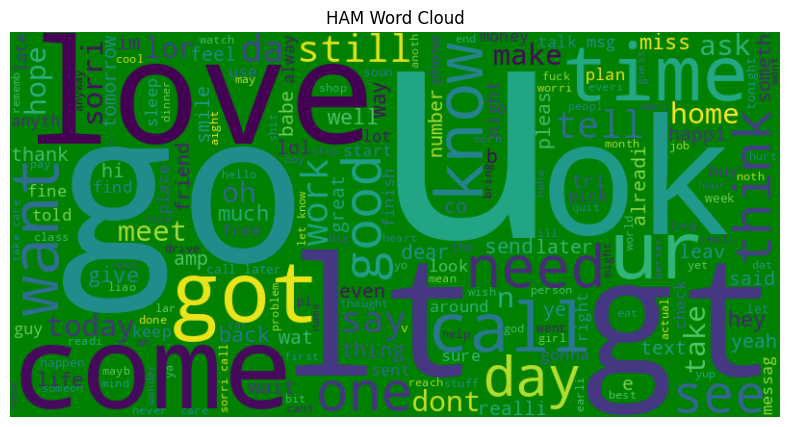

In [399]:
# Ham word cloud

ham_wc = WordCloud(width=800, height=400, background_color='green').generate(' '.join(ham_words))
plt.figure(figsize=(10,5))
plt.imshow(ham_wc, interpolation='bilinear')
plt.axis('off')
plt.title('HAM Word Cloud')
plt.show()

# Step 5 - Feature Engineering

### Feature engineering (Bag of words)

In [400]:
from sklearn.feature_extraction.text import CountVectorizer

### The following commands -
  -Initialize the CountVectorizer
  -Max_feature=2500 means we only keep the top 2500 most frequent words
  -(This reduces the size of the vectors and speed up training)

In [401]:
cv = CountVectorizer(max_features=2500)

### Fit and transform the corpus into a mumerical matrix

In [402]:
X = cv.fit_transform(corpus).toarray()

### Y = the lebels (already numeric from step 3)

In [403]:
Y = df['label_num'].values

In [404]:
print("Shape of X(features):", X.shape)
print("Shape of Y (lebels)", Y.shape)

Shape of X(features): (5572, 2500)
Shape of Y (lebels) (5572,)


### Let's peek at what the vectors look like

In [405]:
print("\nFirst 10 words in our vocabulary:")
print(cv.get_feature_names_out()[:15])


First 10 words in our vocabulary:
['aah' 'aathi' 'abi' 'abiola' 'abl' 'abt' 'abta' 'aburo' 'abus' 'ac'
 'academ' 'acc' 'accept' 'access' 'accid']


### Show the actual text of the first message for comparison

In [406]:
print("\nOriginal first message:", df['message'][0])


Original first message: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...


### Show the Convertion of the first message for comparison

In [407]:
print("\nFirst message converted to numbers (first 30 values):")
print(X[0][:30])


First message converted to numbers (first 30 values):
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### Step 5: Feature Engineering for Logistic Regression.

In [408]:
from sklearn.feature_extraction.text import TfidfVectorizer

##### Initialize TF-IDF

In [409]:
tfidf = TfidfVectorizer(max_features=2500)

#### Transform the cleaned corpus

In [410]:
X_tfidf = tfidf.fit_transform(corpus).toarray()
Y = df['label_num'].values

print("Shape of TF-IDF X", X_tfidf.shape)
print("Shape of Y", Y.shape)

Shape of TF-IDF X (5572, 2500)
Shape of Y (5572,)


#### showing some feature names

In [411]:
print("\nSample words in vocabulary:", tfidf.get_feature_names_out()[:10])


Sample words in vocabulary: ['aah' 'aathi' 'abi' 'abiola' 'abl' 'abt' 'abta' 'aburo' 'abus' 'ac']


### Now comparing Logistic Regression with Naiyeb bayes

In [412]:
print("\nDifference between CountVectorizer and TF-IDF for first message")
print("CountVectorizer (first 10):", X[0][:30])
print("TF-IDF (first 10)  ", X_tfidf[0][:30])


Difference between CountVectorizer and TF-IDF for first message
CountVectorizer (first 10): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
TF-IDF (first 10)   [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]


# Step 6: Model Selection & Training

In [413]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
import numpy as np

# 1. Split the data
### test_size=0.2 → 20% for testing, 80% for training
### random_state=42 → ensures we get the same split every time (reproducibility)

In [414]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

In [415]:
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)


Training set size: (4457, 2500)
Testing set size: (1115, 2500)


### 2. Initialize the model

In [416]:
model = MultinomialNB()

### 3. Train the model
### .fit() is where the actual "learning" happens

In [417]:
model.fit(X_train, Y_train)


MultinomialNB()

### 4. Show class priors

In [418]:
print("\n Model trained successfully!")
print("Number of classes learned:", model.classes_)



 Model trained successfully!
Number of classes learned: [0 1]


### class_count_ = number of samples per class in training data
### class_log_prior_ = log of the prior probability

In [419]:
print("\nClass counts in training data:", model.class_count_)
print("Class log priors:", model.class_log_prior_)


Class counts in training data: [3859.  598.]
Class log priors: [-0.14406781 -2.00864042]


### Convert log priors back to actual probabilities using exp()

In [420]:
priors = np.exp(model.class_log_prior_)
print("Class priors (ham, spam):", priors)

Class priors (ham, spam): [0.86582903 0.13417097]


## Step - 6 : Model Selection & training for Logistic Regression

##### Train/test Split for TF-IDF data

In [421]:
from sklearn.model_selection import train_test_split

X_train_tfidf, X_test_tfidf, Y_train_tfidf, Y_test_tfidf = train_test_split(
    X_tfidf, Y, test_size=0.2, random_state=42, stratify=Y
)

print("Training set size: ", X_train_tfidf.shape)
print("Testing set size: ", X_test_tfidf.shape)

Training set size:  (4457, 2500)
Testing set size:  (1115, 2500)


### Train Logistic Regression

In [422]:
from sklearn.linear_model import LogisticRegression

##### Initialize the model with max_iter=1000 to ensure th runs enough iterations to coverage

In [423]:
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000)

##### Now train the model

In [424]:
lr_model.fit(X_train_tfidf, Y_train_tfidf)

print("Logistic Regression trained successfully..")
print("Number of classes: ", lr_model.classes_)

print("Number of coefficient(features): ", len(lr_model.coef_[0]))

Logistic Regression trained successfully..
Number of classes:  [0 1]
Number of coefficient(features):  2500


### Training vs Testing Metrics

In [425]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [426]:
def get_matrics(model, X_train, Y_train, X_test, Y_test, name):
  """Return training and testing metrics for a classification model."""
  Y_train_pred = model.predict(X_train)
  Y_test_pred = model.predict(X_test)

  train_row = {
      'Model' : name,
      'Split' : 'Training',
      'Accuracy' : accuracy_score(Y_train, Y_train_pred),
      'Precision' : precision_score(Y_train, Y_train_pred),
      'Recall' : recall_score(Y_train, Y_train_pred),
      'F1_Score' : f1_score(Y_train, Y_train_pred)
  }
  test_row = {
      'Model' : name,
      'Split' : 'Testing',
      'Accuracy' : accuracy_score(Y_test, Y_test_pred),
      'Precision' : precision_score(Y_test, Y_test_pred),
      'Recall' : recall_score(Y_test, Y_test_pred),
      'F1_Score' : f1_score(Y_test, Y_test_pred)
  }
  return train_row, test_row


### Naive Bayes (trained on CountVectorizer features)

In [427]:
train_nb, test_nb = get_matrics(
    model, X_train, Y_train, X_test, Y_test, 'Naive Bayes'
)

### Logistic Regression (trained on TF-IDF features)

In [428]:
train_lr, test_lr = get_matrics(
    lr_model, X_train_tfidf, Y_train_tfidf, X_test_tfidf, Y_test_tfidf, 'Logistic Regression'
)

In [429]:
results_df = pd.DataFrame([train_nb, test_nb, train_lr,test_lr])

print("Training vs Testing Metrics")
print("-"*50)
print(results_df.round(4).to_string(index=False))

Training vs Testing Metrics
--------------------------------------------------
              Model    Split  Accuracy  Precision  Recall  F1_Score
        Naive Bayes Training    0.9888     0.9521  0.9649    0.9585
        Naive Bayes  Testing    0.9812     0.9324  0.9262    0.9293
Logistic Regression Training    0.9890     0.9364  0.9849    0.9601
Logistic Regression  Testing    0.9812     0.9384  0.9195    0.9288


### Overfitting analysis

In [430]:
# Overfitting Analysis (compute in loop, print after)

print("\nOVERFITTING ANALYSIS (Accuracy gap = Training − Testing)")
print("=" * 80)

# Collect results from BOTH models in a list
analysis_results = []

for name in ['Naive Bayes', 'Logistic Regression']:
    # Get training accuracy
    train_rows = results_df[(results_df['Model'] == name) & (results_df['Split'] == 'Training')]
    train_acc = float(train_rows['Accuracy'].iloc[0])

    # Get testing accuracy
    test_rows = results_df[(results_df['Model'] == name) & (results_df['Split'] == 'Testing')]
    test_acc = float(test_rows['Accuracy'].iloc[0])

    gap = train_acc - test_acc

    if gap > 0.02:
        verdict = "Possible OVERFITTING"
    elif gap < -0.02:
        verdict = "Possible UNDERFITTING"
    else:
        verdict = "Healthy fit (gap < 2%)"

    # Save to list
    analysis_results.append({
        'name': name,
        'train': train_acc,
        'test': test_acc,
        'gap': gap,
        'verdict': verdict
    })


for result in analysis_results:
    print("{}  Train = {:.4f} | Test = {:.4f} | Gap = {:+.4f}  ->  {}".format(
        result['name'], result['train'], result['test'], result['gap'], result['verdict']
    ))

# Step 3: Sanity check — how many results were collected?
print("\n--- Collected {} models ---".format(len(analysis_results)))


OVERFITTING ANALYSIS (Accuracy gap = Training − Testing)
Naive Bayes  Train = 0.9888 | Test = 0.9812 | Gap = +0.0076  ->  Healthy fit (gap < 2%)
Logistic Regression  Train = 0.9890 | Test = 0.9812 | Gap = +0.0078  ->  Healthy fit (gap < 2%)

--- Collected 2 models ---


In [431]:

# Diagnostic 1: Check what's in results_df
print("Models in results_df:")
print(results_df['Model'].unique())
print("\nFull results_df:")
print(results_df)

Models in results_df:
['Naive Bayes' 'Logistic Regression']

Full results_df:
                 Model     Split  Accuracy  Precision    Recall  F1_Score
0          Naive Bayes  Training  0.988782   0.952145  0.964883  0.958472
1          Naive Bayes   Testing  0.981166   0.932432  0.926174  0.929293
2  Logistic Regression  Training  0.989006   0.936407  0.984950  0.960065
3  Logistic Regression   Testing  0.981166   0.938356  0.919463  0.928814


##### Get vocabulary and coefficients from the trained LR model

In [432]:
feature_names = tfidf.get_feature_names_out()
coefficients  = lr_model.coef_[0]


coef_df = pd.DataFrame({
    'word':        feature_names,
    'coefficient': coefficients
}).sort_values('coefficient', ascending=False).reset_index(drop=True)


In [433]:
print("TOP 15 WORDS PUSHING TOWARD SPAM (positive coefficients)")
print("=" * 60)
print(coef_df.head(15).to_string(index=False))

print("\nTOP 15 WORDS PUSHING TOWARD HAM (most negative coefficients)")
print("=" * 60)
print(coef_df.tail(15).iloc[::-1].to_string(index=False))


TOP 15 WORDS PUSHING TOWARD SPAM (positive coefficients)
  word  coefficient
   txt     5.605358
    uk     4.139171
 claim     3.797491
 mobil     3.748765
 repli     3.641871
servic     3.541890
  call     3.475328
  text     3.430884
  free     3.375987
   www     3.340991
  stop     3.208323
   com     3.022699
 prize     2.897810
   win     2.857028
  chat     2.676533

TOP 15 WORDS PUSHING TOWARD HAM (most negative coefficients)
 word  coefficient
   gt    -2.055000
   lt    -2.024427
   ok    -1.936576
later    -1.846279
sorri    -1.793462
 home    -1.742812
  got    -1.546279
   da    -1.494211
  hey    -1.404982
  sir    -1.388980
  lor    -1.292564
  way    -1.286959
 work    -1.258867
happi    -1.237520
 good    -1.118392


# Step 7: Model Evaluation

In [434]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import seaborn as sns
import matplotlib.pyplot as plt


### 1. Make predictions on the test set

In [435]:
Y_pred = model.predict(X_test)

In [436]:
print(Y_pred)

[0 0 0 ... 0 0 0]


### 2. Calculate metrics

In [437]:
accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred)
recall = recall_score(Y_test, Y_pred)
f1 = f1_score(Y_test, Y_pred)

In [438]:
print("Naive Bayes PERFORMANCE METRICS")
print("="*40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Naive Bayes PERFORMANCE METRICS
Accuracy : 0.9812
Precision: 0.9324
Recall   : 0.9262
F1-Score : 0.9293


### 3. Full classification report

In [439]:
print("\nNaive Bayes DETAILED CLASSIFICATION REPORT")
print("="*40)
print(classification_report(Y_test, Y_pred, target_names=['Ham', 'Spam']))


Naive Bayes DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.93      0.93      0.93       149

    accuracy                           0.98      1115
   macro avg       0.96      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



### 4. Confusion Matrix

In [440]:
cm = confusion_matrix(Y_test, Y_pred)

In [441]:
print("\nNaive Bayes CONFUSION MATRIX")
print("="*40)
print(f"                Predicted Ham   Predicted Spam")
print(f"Actual Ham      {cm[0][0]:<15} {cm[0][1]}")
print(f"Actual Spam     {cm[1][0]:<15} {cm[1][1]}")


Naive Bayes CONFUSION MATRIX
                Predicted Ham   Predicted Spam
Actual Ham      956             10
Actual Spam     11              138


### 5. Visualize the confusion matrix

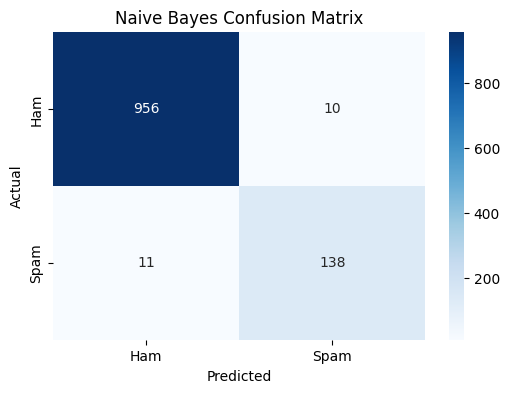

In [442]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'],
            yticklabels=['Ham', 'Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes Confusion Matrix')
plt.show()

### Logistic Regression Evaluation

In [443]:
Y_pred_lr = lr_model.predict(X_test_tfidf)

##### Calculate matrics

In [444]:
print("LOGISTIC REGRESSION PERFORMANCE")
print("="*40)
print(f"Accuracy : {accuracy_score(Y_test_tfidf, Y_pred_lr):.4f}")
print(f"Accuracy : {precision_score(Y_test_tfidf, Y_pred_lr):.4f}")
print(f"Accuracy : {recall_score(Y_test_tfidf, Y_pred_lr):.4f}")
print(f"Accuracy : {f1_score(Y_test_tfidf, Y_pred_lr):.4f}")

LOGISTIC REGRESSION PERFORMANCE
Accuracy : 0.9812
Accuracy : 0.9384
Accuracy : 0.9195
Accuracy : 0.9288


##### Classification Report

In [445]:
print("\nLogistic Regression CLASSIFICATION REPORT")
print("="*40)
print(classification_report(Y_test_tfidf, Y_pred_lr, target_names=['Ham','Spam']))


Logistic Regression CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.94      0.92      0.93       149

    accuracy                           0.98      1115
   macro avg       0.96      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



### Confusion Matrix

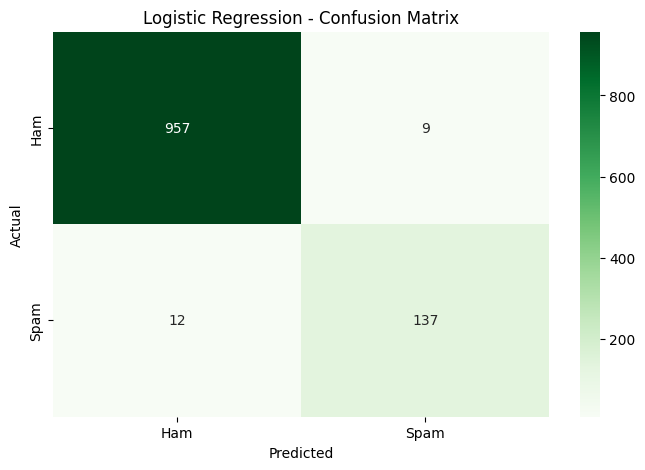

In [446]:
cm_lr = confusion_matrix(Y_test_tfidf, Y_pred_lr)

plt.figure(figsize=(8,5))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', xticklabels=['Ham', 'Spam'], yticklabels=['Ham','Spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

### Comparing Naive Bayes VS Logistic Regression

#### Re-train Naive Bayes on the TF-IDF features for a fair comparison

##### Earlier NB was trained on CountVectorizer; Now we compare on TF-IDF

In [447]:
nb_model_tfidf = MultinomialNB()
nb_model_tfidf.fit(X_train_tfidf, Y_train_tfidf)
Y_pred_nb_tfidf = nb_model_tfidf.predict(X_test_tfidf)

##### Create a comparison table

In [448]:
comparison = pd.DataFrame({
    'Metric':['Accuracy','Precision','Recall','F1-Score'],
    'Naive Bayes (TF-IDF)':[
        accuracy_score(Y_test_tfidf, Y_pred_nb_tfidf),
        precision_score(Y_test_tfidf, Y_pred_nb_tfidf),
        recall_score(Y_test_tfidf, Y_pred_nb_tfidf),
        f1_score(Y_test_tfidf, Y_pred_nb_tfidf)
    ],
    'Logistic Regression (TF-IDF)':[
        accuracy_score(Y_test_tfidf, Y_pred_lr),
        precision_score(Y_test_tfidf, Y_pred_lr),
        recall_score(Y_test_tfidf, Y_pred_lr),
        f1_score(Y_test_tfidf, Y_pred_lr)
    ]
})


print("Model Comparison (Both on TF-IDF)")
print("="*60)
print(comparison.round(4).to_string(index=False))

Model Comparison (Both on TF-IDF)
   Metric  Naive Bayes (TF-IDF)  Logistic Regression (TF-IDF)
 Accuracy                0.9785                        0.9812
Precision                0.9921                        0.9384
   Recall                0.8456                        0.9195
 F1-Score                0.9130                        0.9288


# Step 8: Testing the Model with Custom Messages (Mini "Deployment")

In [449]:
import re
import numpy as np
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

In [450]:
ps = PorterStemmer()

### Data cleanning process repeat as befor in step 3

In [451]:
def clean_message(message):
    """Apply the same cleaning steps used during training."""
    # 1. Remove non-letters
    review = re.sub('[^a-zA-Z]', ' ', message)
    # 2. Lowercase
    review = review.lower()
    # 3. Split into words
    review = review.split()
    # 4. Remove stopwords + stem
    review = [ps.stem(word) for word in review if word not in stopwords.words('english')]
    # 5. Join back
    review = ' '.join(review)
    return review

### Prediction with Naive Bayes

In [452]:
def predict_message(message):
    """Predict if a message is Ham or Spam, with confidence."""
    # Clean it the same way
    cleaned = clean_message(message)

    # Convert to numeric vector using the SAME CountVectorizer
    vector = cv.transform([cleaned]).toarray()

    # Predict
    prediction = model.predict(vector)[0]

    # Get probability (how confident the model is)
    probability = model.predict_proba(vector)[0]

    label = "SPAM" if prediction == 1 else " HAM"
    confidence = probability[prediction] * 100

    print(f"Message   : {message}")
    print(f"Cleaned   : {cleaned}")
    print(f"Prediction: {label}  (confidence: {confidence:.2f}%)")
    print("-" * 60)


### Prediction with Logistic Regression

In [453]:
def predict_with_lr(message):
  """Predict using Logistic Regression with TF-IDF."""
  cleaned = clean_message(message)
  vector = tfidf.transform([cleaned]).toarray()
  prediction = lr_model.predict(vector)[0]
  probability = lr_model.predict_proba(vector)[0]
  label = "SPAM" if prediction == 1 else "HAM"
  confidence = probability[prediction] * 100
  print(f"Message: {message}")
  print(f"Prediction: {label} (confidence: {confidence:.2f}%)")
  print("-" * 60)

# Testing

In [454]:
print("TESTING THE MODEL ON NEW MESSAGES")
print("=" * 60)

# Test messages (mix of obvious spam, obvious ham, and tricky ones)
test_messages = [
    "Hey, are we still meeting for lunch tomorrow?",
    "Congratulations! You've WON a £1000 cash prize. Call 09061701461 to claim now!",
    "Can you pick up some milk on your way home?",
    "URGENT! Your mobile number has been awarded a £2000 bonus. Call now to claim!",
    "Mom, I'll be home late tonight, don't wait up.",
    "Free entry in a weekly competition to win FA Cup final tickets. Text FA to 87121",
    "Just finished my homework, feeling so relieved!",
    "You have 1 new voicemail. Call 08718726270 to listen.",
    "Let's grab coffee this weekend, it's been ages!",
    "WINNER!! You have been selected to receive a £900 prize reward!",
    "Call me when you get home",                              # "call" but NOT spam
    "Free time this weekend, want to hang out?",              # "free" but NOT spam
    "You have won... my heart ",                            # "won" but NOT spam
    "URGENT: Buy milk and eggs on the way home",              # "URGENT" but NOT spam
    "Hey, can you send me the prize list for the office raffle?", # "prize" but context is ham
    "Text me back when you can"                              # "text" but NOT spam

]


print("Testing Messages on Naive Bayes")
print("=" * 50)
for msg in test_messages:
    predict_message(msg)


print("\n\n")


print("Testing Messages on Logistic Regression")
print("=" * 50)
for msg in test_messages:
    predict_with_lr(msg)

TESTING THE MODEL ON NEW MESSAGES
Testing Messages on Naive Bayes
Message   : Hey, are we still meeting for lunch tomorrow?
Cleaned   : hey still meet lunch tomorrow
Prediction:  HAM  (confidence: 100.00%)
------------------------------------------------------------
Message   : Congratulations! You've WON a £1000 cash prize. Call 09061701461 to claim now!
Cleaned   : congratul cash prize call claim
Prediction: SPAM  (confidence: 100.00%)
------------------------------------------------------------
Message   : Can you pick up some milk on your way home?
Cleaned   : pick milk way home
Prediction:  HAM  (confidence: 99.99%)
------------------------------------------------------------
Message   : URGENT! Your mobile number has been awarded a £2000 bonus. Call now to claim!
Cleaned   : urgent mobil number award bonu call claim
Prediction: SPAM  (confidence: 100.00%)
------------------------------------------------------------
Message   : Mom, I'll be home late tonight, don't wait up.
Cleane

## Step 17: Regenerate All Figures

This cell regenerates the six key figures, each labeled with its figure number and axis titles

/tmp/ipykernel_2568/677623748.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


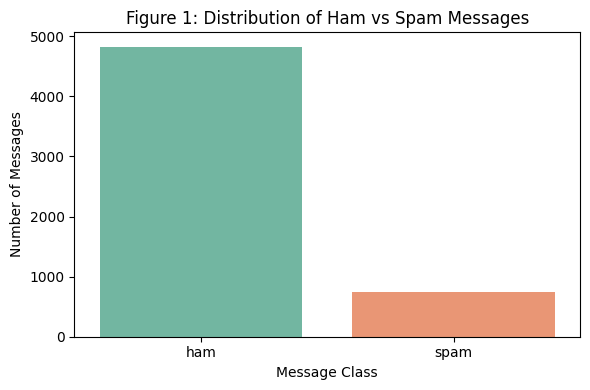

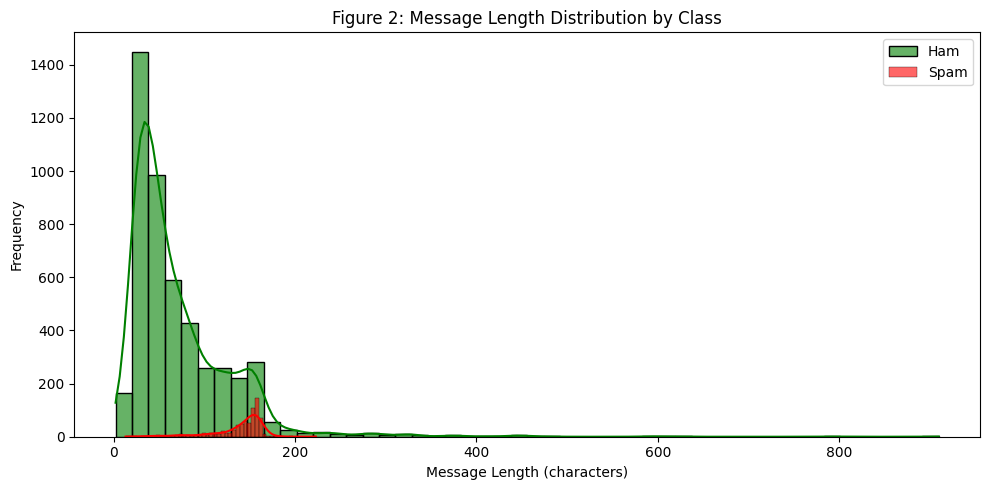

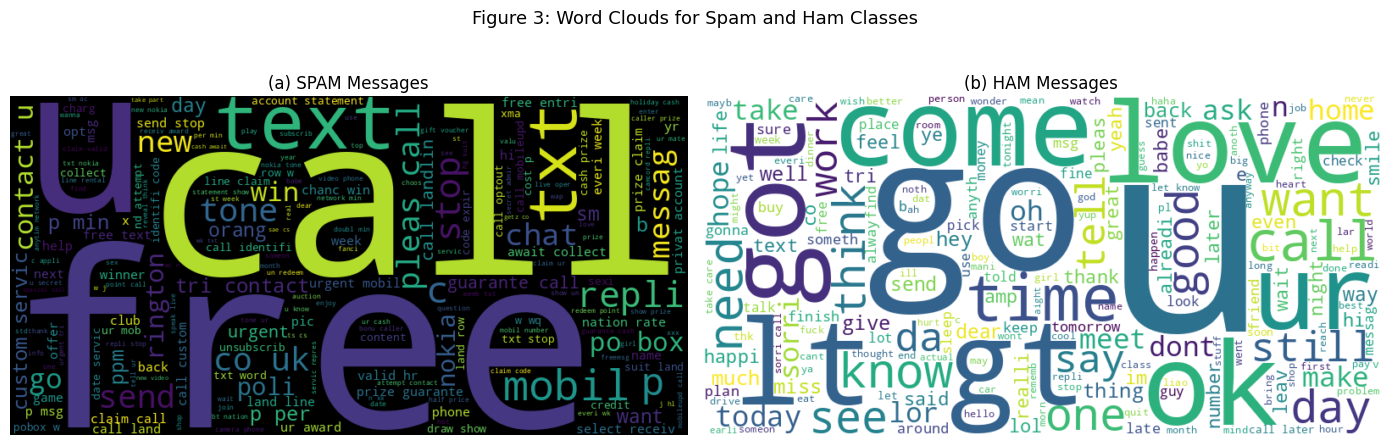

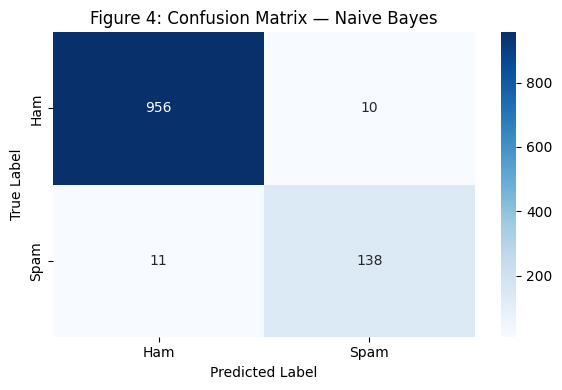

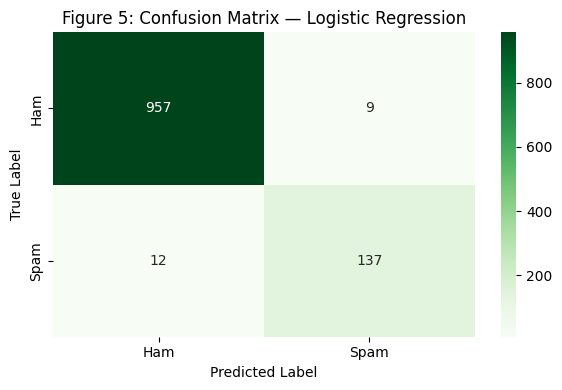

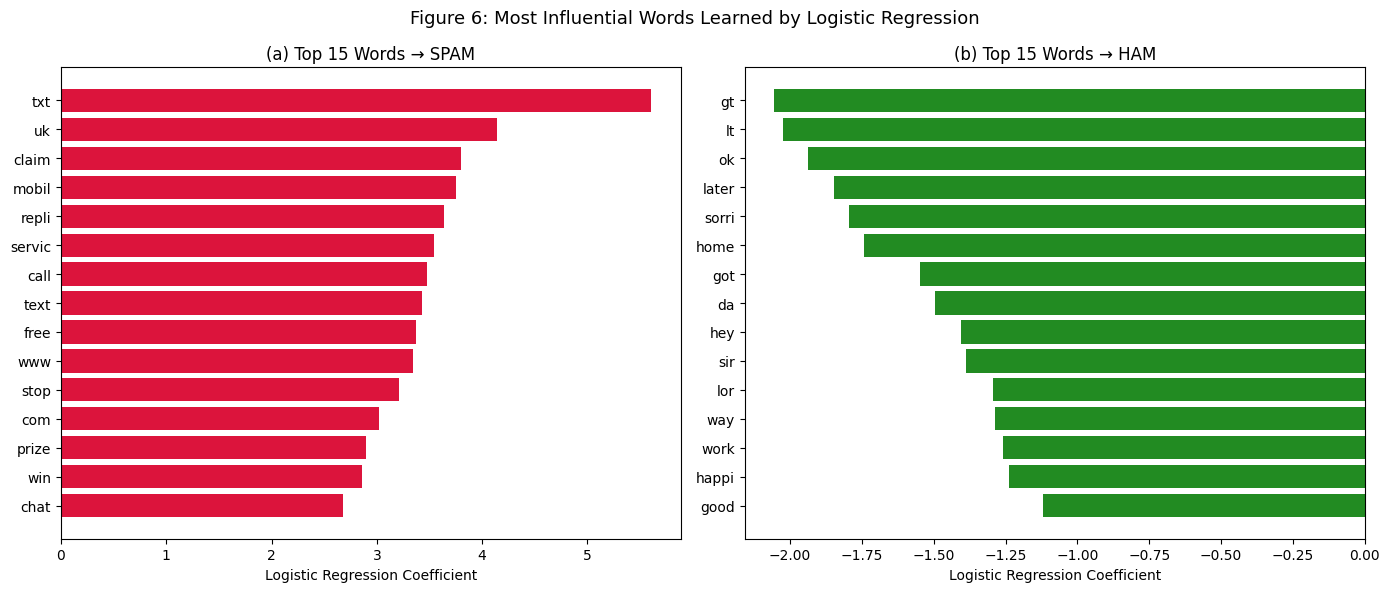

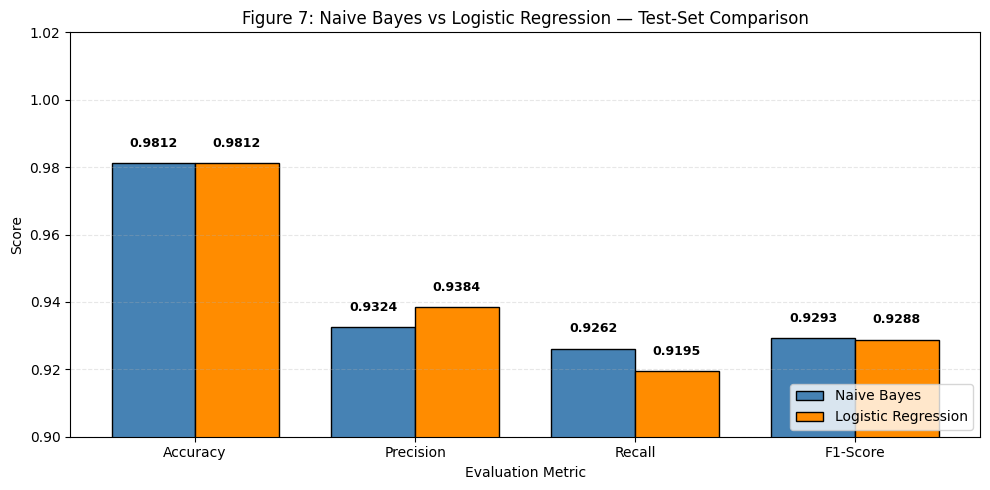





✅ All 7 figures regenerated with numbering, titles, and labeled axes.


In [455]:
# Cell: Regenerate All Figures with Numbers & Captions

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# ======================================================================
# FIGURE 1: Class Distribution
# ======================================================================
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Figure 1: Distribution of Ham vs Spam Messages')
plt.xlabel('Message Class')
plt.ylabel('Number of Messages')
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 2: Message Length Distribution
# ======================================================================
plt.figure(figsize=(10, 5))
sns.histplot(df[df['label'] == 'ham']['length'],  bins=50, color='green', label='Ham',  kde=True, alpha=0.6)
sns.histplot(df[df['label'] == 'spam']['length'], bins=50, color='red',   label='Spam', kde=True, alpha=0.6)
plt.title('Figure 2: Message Length Distribution by Class')
plt.xlabel('Message Length (characters)')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 3: Word Clouds — Spam vs Ham
# ======================================================================
spam_words = ' '.join([corpus[i] for i in range(len(df)) if df['label_num'][i] == 1]).split()
ham_words  = ' '.join([corpus[i] for i in range(len(df)) if df['label_num'][i] == 0]).split()

spam_wc = WordCloud(width=800, height=400, background_color='black').generate(' '.join(spam_words))
ham_wc  = WordCloud(width=800, height=400, background_color='white').generate(' '.join(ham_words))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(spam_wc, interpolation='bilinear'); axes[0].axis('off')
axes[0].set_title('(a) SPAM Messages')
axes[1].imshow(ham_wc, interpolation='bilinear');  axes[1].axis('off')
axes[1].set_title('(b) HAM Messages')
fig.suptitle('Figure 3: Word Clouds for Spam and Ham Classes', fontsize=13)
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 4: Confusion Matrix — Naive Bayes
# ======================================================================
from sklearn.metrics import confusion_matrix
cm_nb = confusion_matrix(Y_test, model.predict(X_test))

plt.figure(figsize=(6, 4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Figure 4: Confusion Matrix — Naive Bayes')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 5: Confusion Matrix — Logistic Regression
# ======================================================================
cm_lr = confusion_matrix(Y_test_tfidf, lr_model.predict(X_test_tfidf))

plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Figure 5: Confusion Matrix — Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 6: Feature Importance (already in M3 — re-emitted for completeness)
# ======================================================================
import pandas as pd
feature_names = tfidf.get_feature_names_out()
coef_df = pd.DataFrame({'word': feature_names, 'coefficient': lr_model.coef_[0]}) \
            .sort_values('coefficient', ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
top_spam = coef_df.head(15).iloc[::-1]
top_ham  = coef_df.tail(15)
axes[0].barh(top_spam['word'], top_spam['coefficient'], color='crimson')
axes[0].set_title('(a) Top 15 Words → SPAM')
axes[0].set_xlabel('Logistic Regression Coefficient')
axes[1].barh(top_ham['word'], top_ham['coefficient'], color='forestgreen')
axes[1].set_title('(b) Top 15 Words → HAM')
axes[1].set_xlabel('Logistic Regression Coefficient')
fig.suptitle('Figure 6: Most Influential Words Learned by Logistic Regression', fontsize=13)
plt.tight_layout()
plt.show()
print("\n\n")
# ======================================================================
# FIGURE 7: NB vs LR Comparison (already in M4 — re-emitted here)
# ======================================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

y_pred_nb = model.predict(X_test)
y_pred_lr = lr_model.predict(X_test_tfidf)

nb_metrics = [accuracy_score(Y_test, Y_pred),
              precision_score(Y_test, Y_pred),
              recall_score(Y_test, Y_pred),
              f1_score(Y_test, Y_pred)]
lr_metrics = [accuracy_score(Y_test_tfidf, Y_pred_lr),
              precision_score(Y_test_tfidf, Y_pred_lr),
              recall_score(Y_test_tfidf, Y_pred_lr),
              f1_score(Y_test_tfidf, Y_pred_lr)]

metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metric_names)); width = 0.38

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, nb_metrics, width, label='Naive Bayes',       color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, lr_metrics, width, label='Logistic Regression', color='darkorange', edgecolor='black')
for bars in (bars1, bars2):
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.004, f'{h:.4f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylabel('Score')
ax.set_xlabel('Evaluation Metric')
ax.set_title('Figure 7: Naive Bayes vs Logistic Regression — Test-Set Comparison')
ax.set_xticks(x); ax.set_xticklabels(metric_names)
ax.set_ylim(0.90, 1.02)
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()
print("\n\n")
print("\n✅ All 7 figures regenerated with numbering, titles, and labeled axes.")
